# Agentic AI Radar — Stage 2: representations and adaptation

**Research question.** Do corpus-trained word embeddings and a compact open language model adapted on the assigned AI Media Dataset capture its language and the Agentic Web track better than transparent reference systems?

**Input.** The full cleaned assigned corpus from `data/processed/articles_clean.parquet`, not only Stage 1's 11,867-article Agentic Web subset. The source/version/cleaning provenance is read from `data/processed/stage1_metadata.json`.

**Model choice.** The professor's brief lists Qwen3-1.7B as a candidate for compact open-model fine-tuning. The selected base model is [`Qwen/Qwen3-1.7B`](https://huggingface.co/Qwen/Qwen3-1.7B), whose model card declares Apache-2.0 and recommends Transformers 4.51.0 or newer; this workflow pins 4.57.1. QLoRA is prepared but was not run in the recorded local execution. This notebook does not download or train the model on the local 8-GiB machine.

**Reproducibility.** Fixed seeds, date-ordered article-level splits, train-only embedding fitting, explicit held-out metrics, and saved split IDs. Stage 1's Agentic Web flag is a keyword-rule output, not gold annotation; its classification results measure agreement with that rule only.

## 1. Runtime, inputs, and reproducibility

Expected inputs are Stage 1's cleaned full corpus and metadata. Paths are relative to the repository root. The local classical workflow needs the packages in `requirements-stage2.txt`; the Colab QLoRA section additionally needs `requirements-stage2-colab.txt`.

The language-model objective is causal next-token prediction on training-partition text. It is self-supervision from article text, not generated Q&A or fabricated labels. Pretrained and adapted models are evaluated on the same fixed test excerpts. Only the LoRA adapter is saved.

In [1]:
from __future__ import annotations

import hashlib
import json
import os
import platform
import random
import re
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

SEED = 20261012
random.seed(SEED)
np.random.seed(SEED)

configured_root = os.environ.get('AGENTIC_RADAR_ROOT')
if configured_root:
    ROOT = Path(configured_root).expanduser().resolve()
else:
    candidates = (Path.cwd(), Path.cwd().parent)
    ROOT = next(
        (candidate for candidate in candidates
         if (candidate / 'data/processed/articles_clean.parquet').is_file()),
        Path.cwd(),
    )

DATA_PATH = ROOT / 'data/processed/articles_clean.parquet'
METADATA_PATH = ROOT / 'data/processed/stage1_metadata.json'
OUTPUT_DIR = ROOT / 'outputs'
TABLE_DIR = OUTPUT_DIR / 'tables'
EVAL_DIR = OUTPUT_DIR / 'evaluations'
MODEL_DIR = OUTPUT_DIR / 'models'
FIGURE_DIR = OUTPUT_DIR / 'figures'
for directory in (TABLE_DIR, EVAL_DIR, MODEL_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.is_file() or not METADATA_PATH.is_file():
    raise FileNotFoundError(
        'Stage 2 requires data/processed/articles_clean.parquet and '
        'data/processed/stage1_metadata.json. In Colab, mount Drive and set '
        "os.environ['AGENTIC_RADAR_ROOT'] to the repository folder containing data/ and outputs/."
    )

metadata = json.loads(METADATA_PATH.read_text())
articles = pd.read_parquet(DATA_PATH)
required = {'article_id', 'text_clean', 'date', 'title', 'is_agentic_web'}
missing = required - set(articles.columns)
if missing:
    raise ValueError(f'Full-corpus input is missing required fields: {sorted(missing)}')
if articles.empty or articles['article_id'].isna().any() or not articles['article_id'].is_unique:
    raise ValueError('Stage 1 corpus must contain rows with unique, non-null article_id values.')
if articles['text_clean'].isna().any() or articles['date'].isna().any():
    raise ValueError('Stage 1 corpus contains null text or dates; repair Stage 1 before training.')
if articles['text_clean'].duplicated().any():
    raise ValueError('Stage 1 corpus contains duplicate cleaned article text; repair Stage 1 before splitting.')

articles['article_id'] = articles['article_id'].astype(str)
articles['date'] = pd.to_datetime(articles['date'], errors='raise').dt.normalize()
articles['is_agentic_web'] = articles['is_agentic_web'].astype(bool)

print({
    'dataset_ref': metadata.get('dataset_ref'),
    'dataset_version': metadata.get('kaggle_dataset_version'),
    'retrieved_at_utc': metadata.get('retrieved_at_utc'),
    'cleaned_articles': len(articles),
    'date_range': [str(articles['date'].min().date()), str(articles['date'].max().date())],
    'agentic_web_rule_flagged': int(articles['is_agentic_web'].sum()),
    'python': sys.version.split()[0],
    'platform': platform.platform(),
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'scikit_learn': sklearn.__version__,
})

{'dataset_ref': 'jannalipenkova/ai-media-dataset', 'dataset_version': '2', 'retrieved_at_utc': '2026-10-11T21:20:19.415542+00:00', 'cleaned_articles': 47443, 'date_range': ['2024-09-11', '2026-08-31'], 'agentic_web_rule_flagged': 11867, 'python': '3.11.9', 'platform': 'macOS-14.6.1-x86_64-i386-64bit', 'pandas': '3.0.5', 'numpy': '2.3.3', 'scikit_learn': '1.7.2'}


## 2. Freeze chronological splits and screen near-duplicates

Dates are kept intact in approximate 80/10/10 train/validation/test partitions. Cross-boundary exact-title and exact-text groups are quarantined. A deterministic SimHash/LSH candidate search compares five-token shingles from the first 4,000 characters, discounts shingles repeated in more than 20 articles, and verifies candidate pairs with full-body shingle Jaccard. Pairs at or above 0.80 are conservatively excluded from all partitions and exported for review; this is an algorithmic quarantine, **not** a human duplicate label. Lower-scoring near-duplicates and variants outside the prefix candidate search may remain, so inspect the exported candidate worksheet before final claims.

In [2]:
split_frame = articles[
    ['article_id', 'date', 'title', 'text_clean', 'is_agentic_web']
].copy()
split_frame['title_group'] = (
    split_frame['title'].fillna('').astype(str).str.casefold()
    .str.replace(r'\s+', ' ', regex=True).str.strip()
)
split_frame['title_group'] = split_frame['title_group'].mask(
    split_frame['title_group'].eq(''),
    'missing-title:' + split_frame['article_id'],
)
split_frame['content_hash_sha256'] = split_frame['text_clean'].map(
    lambda text: hashlib.sha256(str(text).encode('utf-8')).hexdigest()
)

cut_train = split_frame['date'].quantile(0.80).normalize()
cut_validation = split_frame['date'].quantile(0.90).normalize()
split_frame['split'] = np.select(
    [split_frame['date'] <= cut_train, split_frame['date'] <= cut_validation],
    ['train', 'validation'],
    default='test',
)

shingle_pattern = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")
bit_positions = np.arange(64, dtype=np.uint64)
band_mask = (1 << 16) - 1

def article_shingles(text: str, prefix_chars: int | None = None) -> np.ndarray:
    body = str(text) if prefix_chars is None else str(text)[:prefix_chars]
    words = shingle_pattern.findall(body.casefold())
    if len(words) < 50:
        return np.empty(0, dtype=np.uint64)
    hashes = (
        int.from_bytes(
            hashlib.blake2b(
                ' '.join(words[i:i + 5]).encode('utf-8'),
                digest_size=8,
                person=b'agentic-v1',
            ).digest(),
            'big',
        )
        for i in range(len(words) - 4)
    )
    return np.unique(np.fromiter(hashes, dtype=np.uint64))

prefix_shingles = [
    article_shingles(text, prefix_chars=4000)
    for text in split_frame['text_clean']
]
nonempty_shingles = [values for values in prefix_shingles if len(values)]
if not nonempty_shingles:
    raise ValueError('Near-duplicate screening found no usable article shingles.')
unique_shingles, shingle_document_frequency = np.unique(
    np.concatenate(nonempty_shingles), return_counts=True
)
feature_sets = []
signatures = []
for values in prefix_shingles:
    if len(values):
        keep = shingle_document_frequency[np.searchsorted(unique_shingles, values)] <= 20
        values = values[keep]
    feature_sets.append(values)
    if len(values) < 50:
        signatures.append(None)
        continue
    bit_votes = ((values[:, None] >> bit_positions) & 1).sum(axis=0)
    signatures.append(sum(
        1 << bit for bit, votes in enumerate(bit_votes)
        if 2 * votes >= len(values)
    ))
del prefix_shingles, unique_shingles, shingle_document_frequency

band_buckets = {}
for row_index, signature in enumerate(signatures):
    if signature is None:
        continue
    for band in range(4):
        key = (band, (signature >> (band * 16)) & band_mask)
        band_buckets.setdefault(key, []).append(row_index)

row_splits = split_frame['split'].to_numpy()
candidate_index_pairs = set()
for bucket_rows in band_buckets.values():
    for left_position in range(len(bucket_rows) - 1):
        left_index = bucket_rows[left_position]
        for right_index in bucket_rows[left_position + 1:]:
            if row_splits[left_index] != row_splits[right_index]:
                candidate_index_pairs.add((left_index, right_index))
del band_buckets

full_body_cache = {}
near_duplicate_rows = []
row_records = split_frame[
    ['article_id', 'date', 'title', 'split', 'text_clean']
].to_dict('records')
for left_index, right_index in sorted(candidate_index_pairs):
    left_signature = signatures[left_index]
    right_signature = signatures[right_index]
    hamming_distance = (left_signature ^ right_signature).bit_count()
    if hamming_distance > 12:
        continue
    left_features = feature_sets[left_index]
    right_features = feature_sets[right_index]
    if len(left_features) < 50 or len(right_features) < 50:
        continue
    prefix_intersection = np.intersect1d(
        left_features, right_features, assume_unique=True
    ).size
    prefix_jaccard = prefix_intersection / (
        len(left_features) + len(right_features) - prefix_intersection
    )
    if prefix_jaccard < 0.80:
        continue

    for row_index in (left_index, right_index):
        if row_index not in full_body_cache:
            full_body_cache[row_index] = article_shingles(
                row_records[row_index]['text_clean']
            )
    left_full = full_body_cache[left_index]
    right_full = full_body_cache[right_index]
    if len(left_full) < 50 or len(right_full) < 50:
        continue
    full_intersection = np.intersect1d(
        left_full, right_full, assume_unique=True
    ).size
    full_jaccard = full_intersection / (
        len(left_full) + len(right_full) - full_intersection
    )
    if full_jaccard >= 0.80:
        left_record = row_records[left_index]
        right_record = row_records[right_index]
        near_duplicate_rows.append({
            'article_id_a': left_record['article_id'],
            'article_id_b': right_record['article_id'],
            'split_a': left_record['split'],
            'split_b': right_record['split'],
            'published_at_a': left_record['date'],
            'published_at_b': right_record['date'],
            'title_a': left_record['title'],
            'title_b': right_record['title'],
            'prefix_simhash_hamming': hamming_distance,
            'prefix_shingle_jaccard': prefix_jaccard,
            'full_body_shingle_jaccard': full_jaccard,
            'quarantine_threshold': 0.80,
            'algorithmic_quarantine': True,
        })

near_columns = [
    'article_id_a', 'article_id_b', 'split_a', 'split_b',
    'published_at_a', 'published_at_b', 'title_a', 'title_b',
    'prefix_simhash_hamming', 'prefix_shingle_jaccard',
    'full_body_shingle_jaccard', 'quarantine_threshold',
    'algorithmic_quarantine',
]
near_candidates = pd.DataFrame(near_duplicate_rows, columns=near_columns)
near_candidates.to_csv(EVAL_DIR / 'stage2_near_duplicate_candidates.csv', index=False)
near_quarantine_ids = set(near_candidates['article_id_a']) | set(
    near_candidates['article_id_b']
)

crossing_title_groups = (
    split_frame.groupby('title_group')['split'].nunique().loc[lambda values: values > 1].index
)
crossing_content_groups = (
    split_frame.groupby('content_hash_sha256')['split'].nunique().loc[lambda values: values > 1].index
)
reason_by_id = {}
for article_id in split_frame.loc[
    split_frame['title_group'].isin(crossing_title_groups), 'article_id'
]:
    reason_by_id.setdefault(article_id, set()).add('cross_boundary_normalized_title')
for article_id in split_frame.loc[
    split_frame['content_hash_sha256'].isin(crossing_content_groups), 'article_id'
]:
    reason_by_id.setdefault(article_id, set()).add('cross_boundary_exact_text')
for article_id in near_quarantine_ids:
    reason_by_id.setdefault(article_id, set()).add('near_duplicate_candidate_jaccard_ge_0.80')

quarantined = split_frame['article_id'].isin(reason_by_id)
quarantine_export = split_frame.loc[
    quarantined, ['article_id', 'date', 'split', 'title', 'title_group', 'content_hash_sha256']
].copy()
quarantine_export['quarantine_reason'] = quarantine_export['article_id'].map(
    lambda article_id: ';'.join(sorted(reason_by_id[article_id]))
)
quarantine_export.rename(columns={'date': 'published_at'}).to_csv(
    EVAL_DIR / 'stage2_quarantined_articles.csv', index=False
)
quarantined_article_ids = split_frame.loc[quarantined, 'article_id'].tolist()
split_frame = split_frame.loc[~quarantined].copy()

assert split_frame['article_id'].is_unique
assert not split_frame.groupby('title_group')['split'].nunique().gt(1).any()
assert not split_frame.groupby('content_hash_sha256')['split'].nunique().gt(1).any()
remaining_ids = set(split_frame['article_id'])
assert not any(
    left in remaining_ids and right in remaining_ids
    for left, right in zip(near_candidates['article_id_a'], near_candidates['article_id_b'])
)
for earlier, later in [('train', 'validation'), ('validation', 'test')]:
    earlier_max = split_frame.loc[split_frame['split'].eq(earlier), 'date'].max()
    later_min = split_frame.loc[split_frame['split'].eq(later), 'date'].min()
    assert earlier_max < later_min, f'{earlier}/{later} date boundary overlaps'

split_ids = split_frame[
    ['article_id', 'date', 'split', 'title_group', 'content_hash_sha256']
].rename(columns={'date': 'published_at'})
split_ids.to_csv(EVAL_DIR / 'stage2_split_ids.csv', index=False)
split_counts = split_frame.groupby('split').agg(
    articles=('article_id', 'size'),
    first_date=('date', 'min'),
    last_date=('date', 'max'),
)
print('Chronological cutoffs:', cut_train.date(), cut_validation.date())
print('Cross-boundary duplicate title groups:', len(crossing_title_groups))
print('Cross-boundary exact-text groups:', len(crossing_content_groups))
print('Near-duplicate candidate pairs quarantined:', len(near_candidates))
print('Unique quarantined articles:', len(quarantined_article_ids))
display(split_counts)

split_lookup = split_frame.set_index('article_id')['split']
articles = articles.loc[articles['article_id'].isin(split_lookup.index)].copy()
articles['split'] = articles['article_id'].map(split_lookup)
train_articles = articles.loc[articles['split'].eq('train')].copy()
validation_articles = articles.loc[articles['split'].eq('validation')].copy()
test_articles = articles.loc[articles['split'].eq('test')].copy()
assert len(train_articles) + len(validation_articles) + len(test_articles) == len(articles)
assert set(train_articles['article_id']).isdisjoint(validation_articles['article_id'])
assert set(train_articles['article_id']).isdisjoint(test_articles['article_id'])

Chronological cutoffs: 2026-04-24 2026-06-09
Cross-boundary duplicate title groups: 10
Cross-boundary exact-text groups: 0
Near-duplicate candidate pairs quarantined: 26
Unique quarantined articles: 68


,articles,first_date,last_date
split,,,
test,4653,2026-06-10,2026-08-31
train,38002,2024-09-11,2026-04-24
validation,4720,2026-04-25,2026-06-09


## 3. Train Word2Vec on training text only

Skip-gram with negative sampling is trained from scratch on sentence-like spans from all training-partition articles. A single worker and fixed seed favor reproducibility over speed. The test partition is used only for intrinsic context-pair evaluation and the held-out extrinsic task.

In [3]:
try:
    import gensim
    from gensim.models import Word2Vec
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        'Install the pinned local dependencies with `pip install -r requirements-stage2.txt`.'
    ) from exc

TOKEN_PATTERN = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")
SENTENCE_BOUNDARY = re.compile(r'(?<=[.!?])\s+')

def tokenize(text: str) -> list[str]:
    return TOKEN_PATTERN.findall(str(text).casefold())

class ArticleSentences:
    def __init__(self, texts: list[str]):
        self.texts = texts

    def __iter__(self):
        for text in self.texts:
            for sentence in SENTENCE_BOUNDARY.split(text):
                tokens = tokenize(sentence)
                if len(tokens) >= 2:
                    yield tokens

train_texts = train_articles['text_clean'].astype(str).tolist()
WORD2VEC_CONFIG = {
    'vector_size': 100,
    'window': 5,
    'min_count': 5,
    'sg': 1,
    'negative': 5,
    'epochs': 3,
    'workers': 1,
    'seed': SEED,
}
word2vec_path = MODEL_DIR / 'stage2_word2vec.model'
word2vec_metadata_path = TABLE_DIR / 'stage2_word2vec_metadata.json'
training_ids_sha256 = hashlib.sha256(
    '\n'.join(sorted(train_articles['article_id'])).encode('utf-8')
).hexdigest()
cache_matches = False
if word2vec_path.is_file() and word2vec_metadata_path.is_file():
    cached_metadata = json.loads(word2vec_metadata_path.read_text())
    cache_matches = (
        cached_metadata.get('dataset_version') == metadata.get('kaggle_dataset_version')
        and cached_metadata.get('training_ids_sha256') == training_ids_sha256
        and cached_metadata.get('config') == WORD2VEC_CONFIG
        and cached_metadata.get('gensim') == gensim.__version__
    )

if cache_matches:
    word2vec = Word2Vec.load(str(word2vec_path))
    word2vec_seconds = float(cached_metadata['training_seconds'])
    word2vec_source = 'validated local cache'
else:
    w2v_started = time.perf_counter()
    word2vec = Word2Vec(
        sentences=ArticleSentences(train_texts),
        vector_size=WORD2VEC_CONFIG['vector_size'],
        window=WORD2VEC_CONFIG['window'],
        min_count=WORD2VEC_CONFIG['min_count'],
        sg=WORD2VEC_CONFIG['sg'],
        negative=WORD2VEC_CONFIG['negative'],
        epochs=WORD2VEC_CONFIG['epochs'],
        workers=WORD2VEC_CONFIG['workers'],
        seed=WORD2VEC_CONFIG['seed'],
    )
    word2vec_seconds = time.perf_counter() - w2v_started
    word2vec.save(str(word2vec_path))
    word2vec_metadata = {
        'dataset_ref': metadata.get('dataset_ref'),
        'dataset_version': metadata.get('kaggle_dataset_version'),
        'training_articles': len(train_articles),
        'training_ids_sha256': training_ids_sha256,
        'config': WORD2VEC_CONFIG,
        'gensim': gensim.__version__,
        'training_seconds': word2vec_seconds,
        'model_path': str(word2vec_path.relative_to(ROOT)),
    }
    word2vec_metadata_path.write_text(json.dumps(word2vec_metadata, indent=2))
    word2vec_source = 'trained in this run'
print({
    'gensim': gensim.__version__,
    'training_articles': len(train_articles),
    'vocabulary_size': len(word2vec.wv),
    'config': WORD2VEC_CONFIG,
    'training_seconds': round(word2vec_seconds, 1),
    'model_source': word2vec_source,
    'saved_model': str(word2vec_path.relative_to(ROOT)),
})

{'gensim': '4.4.0', 'training_articles': 38002, 'vocabulary_size': 95445, 'config': {'vector_size': 100, 'window': 5, 'min_count': 5, 'sg': 1, 'negative': 5, 'epochs': 3, 'workers': 1, 'seed': 20261012}, 'training_seconds': 1011.7, 'model_source': 'validated local cache', 'saved_model': 'outputs/models/stage2_word2vec.model'}


## 4. Qualitative Agentic Web neighbors

Nearest neighbors are descriptive examples, not evidence that two concepts are interchangeable or factually related. Missing query terms are reported as out-of-vocabulary rather than silently substituted.

In [4]:
TRACK_QUERIES = ['agent', 'agents', 'agentic', 'mcp', 'langgraph', 'autogen', 'openai', 'anthropic']
neighbor_rows = []
for query in TRACK_QUERIES:
    if query not in word2vec.wv:
        neighbor_rows.append({'query': query, 'rank': None, 'neighbor': None, 'cosine_similarity': None,
                              'status': 'out_of_vocabulary'})
        continue
    for rank, (neighbor, similarity) in enumerate(word2vec.wv.most_similar(query, topn=8), start=1):
        neighbor_rows.append({
            'query': query,
            'rank': rank,
            'neighbor': neighbor,
            'cosine_similarity': float(similarity),
            'status': 'trained_neighbor',
        })
neighbors = pd.DataFrame(neighbor_rows)
neighbors.to_csv(TABLE_DIR / 'stage2_word2vec_neighbors.csv', index=False)
display(neighbors)

,query,rank,neighbor,cosine_similarity,status
0,agent,1,agents,0.787724,trained_neighbor
1,agent,2,subagent,0.772008,trained_neighbor
2,agent,3,a2h,0.763807,trained_neighbor
3,agent,4,slackbot,0.751662,trained_neighbor
4,agent,5,orchestrator,0.749643,trained_neighbor
...,...,...,...,...,...
59,anthropic,4,mythos,0.778693,trained_neighbor
60,anthropic,5,claude,0.778637,trained_neighbor
61,anthropic,6,openai's,0.772018,trained_neighbor
62,anthropic,7,xai,0.765135,trained_neighbor


## 5. Intrinsic held-out context-pair test

Positive content-word pairs are sampled from local context windows in held-out test articles. Stopwords and tokens with fewer than 10 training occurrences are excluded; random negative pairs are matched to the positive endpoints' log-frequency bins and exclude sampled positives. ROC-AUC measures whether cosine similarity ranks held-out observed context pairs above these frequency-matched negatives. This remains a noisy corpus-derived proxy, not a human semantic-similarity benchmark.

In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import roc_auc_score

pair_rng = random.Random(SEED)
positive_pairs = set()
sampled_test = test_articles.sample(n=min(1200, len(test_articles)), random_state=SEED)
word_counts = {
    token: word2vec.wv.get_vecattr(token, 'count')
    for token in word2vec.wv.index_to_key
}
eligible_counts = {
    token: count for token, count in word_counts.items()
    if len(token) >= 3 and token not in ENGLISH_STOP_WORDS and count >= 10
}
def frequency_bin(count):
    return min(9, int(np.log10(count)))

frequency_buckets = {
    bucket: [token for token, count in eligible_counts.items() if frequency_bin(count) == bucket]
    for bucket in range(10)
}
for text in sampled_test['text_clean'].astype(str):
    tokens = [token for token in tokenize(text[:6000]) if token in eligible_counts]
    if len(tokens) < 3:
        continue
    centers = min(8, len(tokens))
    for _ in range(centers):
        center = pair_rng.randrange(len(tokens))
        left = max(0, center - 5)
        right = min(len(tokens), center + 6)
        candidates = [pos for pos in range(left, right) if pos != center]
        if candidates:
            other = pair_rng.choice(candidates)
            pair = tuple(sorted((tokens[center], tokens[other])))
            if pair[0] != pair[1]:
                positive_pairs.add(pair)
        if len(positive_pairs) >= 5000:
            break
    if len(positive_pairs) >= 5000:
        break

if len(positive_pairs) < 500:
    raise ValueError(f'Only {len(positive_pairs)} usable held-out positive pairs were found.')
negative_pairs = set()
for left, right in sorted(positive_pairs):
    left_bucket = frequency_buckets[frequency_bin(eligible_counts[left])]
    right_bucket = frequency_buckets[frequency_bin(eligible_counts[right])]
    for _ in range(5000):
        pair = tuple(sorted((pair_rng.choice(left_bucket), pair_rng.choice(right_bucket))))
        if pair[0] != pair[1] and pair not in positive_pairs and pair not in negative_pairs:
            negative_pairs.add(pair)
            break

if len(negative_pairs) != len(positive_pairs):
    raise ValueError('Could not construct a full frequency-matched negative sample.')

evaluation_pairs = sorted(positive_pairs) + sorted(negative_pairs)
pair_labels = np.r_[np.ones(len(positive_pairs)), np.zeros(len(negative_pairs))]
pair_scores = np.array([
    word2vec.wv.similarity(left, right) for left, right in evaluation_pairs
])
context_auc = float(roc_auc_score(pair_labels, pair_scores))
intrinsic_result = {
    'stage': 'embeddings',
    'model': 'word2vec_sg_ns',
    'metric': 'heldout_context_pair_roc_auc',
    'value': context_auc,
    'n': len(evaluation_pairs),
    'notes': 'Held-out content-word context pairs; random negatives matched by training-frequency bins; not independently verified labels.',
}
print(intrinsic_result)

{'stage': 'embeddings', 'model': 'word2vec_sg_ns', 'metric': 'heldout_context_pair_roc_auc', 'value': 0.6774604799999999, 'n': 10000, 'notes': 'Held-out content-word context pairs; random negatives matched by training-frequency bins; not independently verified labels.'}


## 6. Held-out extrinsic rule-label classification

Compare a train-only TF-IDF baseline, mean Word2Vec article vectors, and a majority-class baseline on the chronological test partition. The target is Stage 1's keyword-rule flag, not a reviewed or gold Agentic Web annotation; these scores measure agreement with that heuristic only.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support,
)

y_train = train_articles['is_agentic_web'].astype(bool).to_numpy()
y_test = test_articles['is_agentic_web'].astype(bool).to_numpy()
if len(np.unique(y_train)) != 2 or len(np.unique(y_test)) != 2:
    raise ValueError('Rule-label evaluation requires both classes in train and test.')

extrinsic_rows = []

def record_rule_metrics(name, predictions, feature_count):
    base_metrics = (
        ('macro_f1', f1_score(y_test, predictions, average='macro', zero_division=0)),
        ('accuracy', accuracy_score(y_test, predictions)),
    )
    for metric, value in base_metrics:
        extrinsic_rows.append({
            'stage': 'embeddings',
            'model': name,
            'metric': metric,
            'value': float(value),
            'n': len(y_test),
            'notes': (
                'Chronological held-out agreement with Stage 1 keyword-rule flag; '
                f'not gold annotation. Features={feature_count}.'
            ),
        })
    precision, recall, _, support = precision_recall_fscore_support(
        y_test, predictions, labels=[False, True], zero_division=0
    )
    for index, label in enumerate(('weak_negative', 'weak_positive')):
        for metric, value in (('precision', precision[index]), ('recall', recall[index])):
            extrinsic_rows.append({
                'stage': 'embeddings',
                'model': name,
                'metric': f'{metric}_{label}',
                'value': float(value),
                'n': int(support[index]),
                'notes': 'Per-class agreement with the weak Stage 1 keyword-rule label; not gold annotation.',
            })
    for metric, value in zip(
        ('true_negative_count', 'false_positive_count', 'false_negative_count', 'true_positive_count'),
        confusion_matrix(y_test, predictions, labels=[False, True]).ravel(),
    ):
        extrinsic_rows.append({
            'stage': 'embeddings',
            'model': name,
            'metric': metric,
            'value': int(value),
            'n': len(y_test),
            'notes': 'Confusion count against weak Stage 1 keyword-rule labels; not semantic errors.',
        })

rule_predictions = {}
majority = DummyClassifier(strategy='most_frequent')
majority.fit(np.zeros((len(y_train), 1)), y_train)
rule_predictions['majority_rule_flag'] = majority.predict(np.zeros((len(y_test), 1)))
record_rule_metrics(
    'majority_rule_flag', rule_predictions['majority_rule_flag'], 1
)

tfidf = TfidfVectorizer(
    max_features=50000,
    min_df=2,
    max_df=0.95,
    stop_words='english',
    sublinear_tf=True,
    dtype=np.float32,
)
x_train_tfidf = tfidf.fit_transform(train_articles['text_clean'].astype(str))
x_test_tfidf = tfidf.transform(test_articles['text_clean'].astype(str))
tfidf_classifier = LogisticRegression(
    max_iter=500, class_weight='balanced', random_state=SEED
)
tfidf_classifier.fit(x_train_tfidf, y_train)
rule_predictions['tfidf_logistic_regression'] = tfidf_classifier.predict(x_test_tfidf)
record_rule_metrics(
    'tfidf_logistic_regression',
    rule_predictions['tfidf_logistic_regression'],
    x_train_tfidf.shape[1],
)
del x_train_tfidf, x_test_tfidf, tfidf_classifier, tfidf

def mean_word2vec(text):
    vectors = [
        word2vec.wv[token]
        for token in tokenize(text)
        if token in word2vec.wv
    ]
    if not vectors:
        return np.zeros(word2vec.vector_size, dtype=np.float32)
    return np.mean(vectors, axis=0, dtype=np.float32)

x_train_w2v = np.vstack([
    mean_word2vec(text) for text in train_articles['text_clean'].astype(str)
])
x_test_w2v = np.vstack([
    mean_word2vec(text) for text in test_articles['text_clean'].astype(str)
])
w2v_classifier = LogisticRegression(
    max_iter=500, class_weight='balanced', random_state=SEED
)
w2v_classifier.fit(x_train_w2v, y_train)
rule_predictions['mean_word2vec_logistic_regression'] = w2v_classifier.predict(x_test_w2v)
record_rule_metrics(
    'mean_word2vec_logistic_regression',
    rule_predictions['mean_word2vec_logistic_regression'],
    word2vec.vector_size,
)
prediction_frame = pd.DataFrame({
    'article_id': test_articles['article_id'].to_numpy(),
    'published_at': test_articles['date'].dt.date.astype(str).to_numpy(),
    'title': test_articles['title'].to_numpy(),
    'weak_rule_label': y_test,
})
for model_name, predictions in rule_predictions.items():
    prediction_frame[f'{model_name}_prediction'] = np.asarray(predictions, dtype=bool)
    prediction_frame[f'{model_name}_disagrees_with_rule'] = predictions != y_test
prediction_frame.to_csv(EVAL_DIR / 'stage2_rule_label_predictions.csv', index=False)
print('Disagreements with weak rule labels:', {
    model_name: int(np.count_nonzero(predictions != y_test))
    for model_name, predictions in rule_predictions.items()
})
print(pd.DataFrame(extrinsic_rows))

Disagreements with weak rule labels: {'majority_rule_flag': 1746, 'tfidf_logistic_regression': 394, 'mean_word2vec_logistic_regression': 884}
         stage                              model                   metric  \
0   embeddings                 majority_rule_flag                 macro_f1   
1   embeddings                 majority_rule_flag                 accuracy   
2   embeddings                 majority_rule_flag  precision_weak_negative   
3   embeddings                 majority_rule_flag     recall_weak_negative   
4   embeddings                 majority_rule_flag  precision_weak_positive   
5   embeddings                 majority_rule_flag     recall_weak_positive   
6   embeddings                 majority_rule_flag      true_negative_count   
7   embeddings                 majority_rule_flag     false_positive_count   
8   embeddings                 majority_rule_flag     false_negative_count   
9   embeddings                 majority_rule_flag      true_positive_count   


## 7. Visualize track vocabulary and save embedding results

PCA is used only as a readable two-dimensional projection; distances in the plot are not an evaluation metric. The generated result files include the held-out intrinsic and rule-label agreement comparisons.

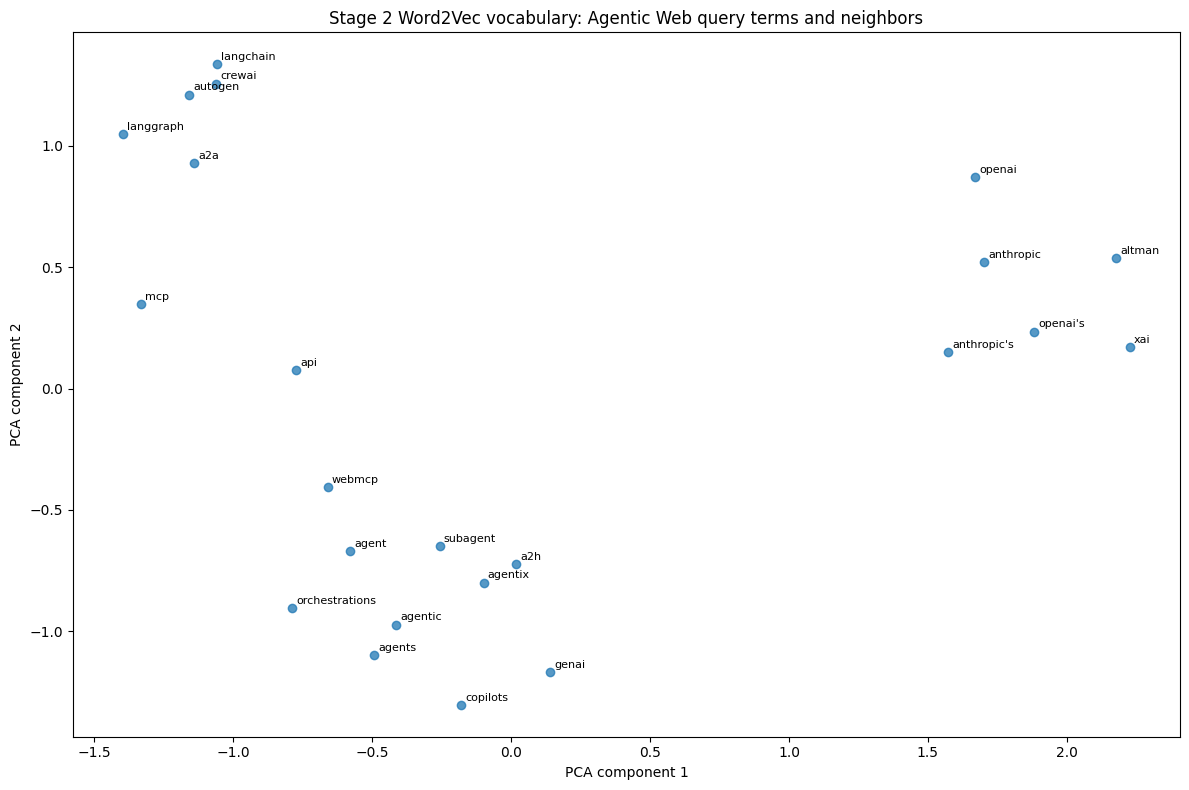

,stage,model,metric,value,n,notes
0,embeddings,word2vec_sg_ns,heldout_context_pair_roc_auc,0.677460,10000,Held-out content-word context pairs; random ne...
1,embeddings,majority_rule_flag,macro_f1,0.384524,4653,Chronological held-out agreement with Stage 1 ...
2,embeddings,majority_rule_flag,accuracy,0.624758,4653,Chronological held-out agreement with Stage 1 ...
3,embeddings,majority_rule_flag,precision_weak_negative,0.624758,2907,Per-class agreement with the weak Stage 1 keyw...
4,embeddings,majority_rule_flag,recall_weak_negative,1.000000,2907,Per-class agreement with the weak Stage 1 keyw...
5,embeddings,majority_rule_flag,precision_weak_positive,0.000000,1746,Per-class agreement with the weak Stage 1 keyw...
6,embeddings,majority_rule_flag,recall_weak_positive,0.000000,1746,Per-class agreement with the weak Stage 1 keyw...
7,embeddings,majority_rule_flag,true_negative_count,2907.000000,4653,Confusion count against weak Stage 1 keyword-r...
8,embeddings,majority_rule_flag,false_positive_count,0.000000,4653,Confusion count against weak Stage 1 keyword-r...
9,embeddings,majority_rule_flag,false_negative_count,1746.000000,4653,Confusion count against weak Stage 1 keyword-r...


In [7]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

plot_terms = []
for term in TRACK_QUERIES:
    if term in word2vec.wv:
        plot_terms.append(term)
        plot_terms.extend(
            neighbor for neighbor, _ in word2vec.wv.most_similar(term, topn=3)
            if neighbor not in plot_terms
        )
plot_terms = list(dict.fromkeys(plot_terms))
if len(plot_terms) < 3:
    raise ValueError('Fewer than three Agentic Web query/neighbor terms are available for PCA.')
coordinates = PCA(n_components=2, random_state=SEED).fit_transform(
    np.vstack([word2vec.wv[term] for term in plot_terms])
)
figure, axis = plt.subplots(figsize=(12, 8))
axis.scatter(coordinates[:, 0], coordinates[:, 1], alpha=0.75)
for term, (x, y) in zip(plot_terms, coordinates):
    axis.annotate(term, (x, y), fontsize=8, xytext=(3, 3), textcoords='offset points')
axis.set_title('Stage 2 Word2Vec vocabulary: Agentic Web query terms and neighbors')
axis.set_xlabel('PCA component 1')
axis.set_ylabel('PCA component 2')
figure.tight_layout()
figure.savefig(FIGURE_DIR / 'stage2_agentic_embeddings_pca.png', dpi=180)
plt.show()

all_embedding_results = pd.DataFrame([intrinsic_result] + extrinsic_rows)
all_embedding_results = pd.concat([
    all_embedding_results,
    pd.DataFrame([{
        'stage': 'embeddings',
        'model': 'word2vec_sg_ns',
        'metric': 'training_seconds',
        'value': float(word2vec_seconds),
        'n': len(train_articles),
        'notes': f'Python={sys.version.split()[0]}; gensim={gensim.__version__}; workers=1.',
    }]),
], ignore_index=True)
all_embedding_results.to_csv(EVAL_DIR / 'stage2_metrics.csv', index=False)
all_embedding_results.to_csv(TABLE_DIR / 'stage2_embedding_metrics.csv', index=False)
display(all_embedding_results)

**Runtime and cost controls.** A compatible CUDA runtime is required; the assignment names Colab Pro or a similar environment but does not establish that a paid Pro runtime is necessary. This notebook never starts a paid session. In the recorded local run, QLoRA is `BLOCKED` and no model weights were downloaded. In Colab, mount Drive and set `AGENTIC_RADAR_ROOT` to the project folder containing the Stage 1 Parquet and metadata; install `requirements-stage2-colab.txt`. Review the runtime's GPU and memory report first; the download/training cell stays blocked until `ENABLE_QLORA_RUN = True` is set deliberately.

**Objective:** one epoch of causal next-token adaptation on training-partition article text, using 4-bit NF4 quantization and LoRA. All training text is eligible by default; a finite `MAX_TRAIN_CHUNKS` is only a smoke-test cap and must be reported as such. The pretrained and adapted models are compared on identical seeded test excerpts stratified by publication month and the Stage 1 rule flag; paired bootstrap intervals are over per-article excerpt losses. Test data is not used for gradient updates.

In [8]:
MODEL_ID = 'Qwen/Qwen3-1.7B'
MAX_LENGTH = 512
MAX_TRAIN_CHUNKS = None
MAX_EVAL_ARTICLES = 256
NUM_EPOCHS = 1
BATCH_SIZE = 1
GRADIENT_ACCUMULATION_STEPS = 16
LEARNING_RATE = 2e-4
LORA_RANK = 8

ENABLE_QLORA_RUN = False

qlora_status = 'BLOCKED'
if not os.environ.get('COLAB_RELEASE_TAG'):
    qlora_reason = (
        'No Colab CUDA runtime was detected. No model weights were downloaded. '
        'Select a suitable CUDA runtime, install requirements-stage2-colab.txt, '
        'and review its cost and GPU memory before opting in.'
    )
    print('BLOCKED — Qwen3-1.7B QLoRA was not downloaded or trained.')
    print(qlora_reason)
else:
    import torch
    if not torch.cuda.is_available():
        qlora_reason = 'Colab CUDA GPU is unavailable; select a GPU runtime before training.'
        print('BLOCKED — Qwen3-1.7B QLoRA was not downloaded or trained.')
        print(qlora_reason)
    else:
        gpu_properties = torch.cuda.get_device_properties(0)
        print({
            'gpu': gpu_properties.name,
            'total_vram_gib': round(gpu_properties.total_memory / (1024 ** 3), 2),
        })
        import importlib.util
        missing_packages = [
            package for package in ('transformers', 'peft', 'bitsandbytes', 'accelerate')
            if importlib.util.find_spec(package) is None
        ]
        if missing_packages:
            qlora_reason = (
                f'Missing Colab packages: {missing_packages}. Install requirements-stage2-colab.txt '
                'in the CUDA runtime, restart the runtime, and rerun.'
            )
            print('BLOCKED — Qwen3-1.7B QLoRA was not downloaded or trained.')
            print(qlora_reason)
        elif not ENABLE_QLORA_RUN:
            qlora_reason = (
                'CUDA is available, but model download and training remain explicitly disabled. '
                'Review runtime availability and cost, then set ENABLE_QLORA_RUN = True to proceed.'
            )
            print('BLOCKED — Qwen3-1.7B QLoRA was not downloaded or trained.')
            print(qlora_reason)
        else:
            qlora_status = 'READY'
            qlora_reason = 'Colab CUDA and required QLoRA packages are available; run the next cell.'
            print(qlora_reason)

BLOCKED — Qwen3-1.7B QLoRA was not downloaded or trained.
No Colab CUDA runtime was detected. No model weights were downloaded. Select a suitable CUDA runtime, install requirements-stage2-colab.txt, and review its cost and GPU memory before opting in.


In [9]:
if qlora_status != 'READY':
    print(f'BLOCKED — adaptation cell skipped: {qlora_reason}')
else:
    from torch.utils.data import DataLoader, IterableDataset
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
    from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
    from bitsandbytes.optim import PagedAdamW8bit

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    compute_dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    quantization = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type='nf4',
        bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=compute_dtype,
    )
    torch.cuda.reset_peak_memory_stats()
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    base_model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        quantization_config=quantization,
        device_map='auto',
    )
    model_revision = getattr(base_model.config, '_commit_hash', None)
    base_model.config.use_cache = False

    def fixed_eval_examples(frame, limit, seed, partition):
        candidates = frame.copy()
        candidates['eval_month'] = pd.to_datetime(candidates['date']).dt.to_period('M').astype(str)
        groups = list(candidates.groupby(
            ['eval_month', 'is_agentic_web'], sort=True, dropna=False
        ))
        target_size = min(limit, len(candidates))
        if not groups or target_size == 0:
            raise ValueError(f'No {partition} articles are available for evaluation.')
        base, remainder = divmod(target_size, len(groups))
        selected_groups = []
        for group_index, (_, group) in enumerate(groups):
            take = min(len(group), base + int(group_index < remainder))
            if take:
                selected_groups.append(group.sample(
                    n=take, random_state=seed + group_index
                ))
        selected = pd.concat(selected_groups) if selected_groups else candidates.iloc[:0]
        if len(selected) < target_size:
            remaining = candidates.loc[~candidates['article_id'].isin(selected['article_id'])]
            selected = pd.concat([
                selected,
                remaining.sample(
                    n=target_size - len(selected), random_state=seed + len(groups)
                ),
            ])
        selected = selected.sort_values(
            ['date', 'article_id'], kind='stable'
        ).reset_index(drop=True)

        examples = []
        manifest_rows = []
        for row in selected.itertuples(index=False):
            token_ids = tokenizer.encode(row.text_clean, add_special_tokens=False)
            if len(token_ids) < 16:
                continue
            max_start = max(0, len(token_ids) - MAX_LENGTH)
            article_seed = int.from_bytes(
                hashlib.blake2b(
                    f'{seed}:{row.article_id}'.encode('utf-8'), digest_size=8
                ).digest(),
                'big',
            )
            token_start = random.Random(article_seed).randint(0, max_start)
            excerpt = token_ids[token_start:token_start + MAX_LENGTH]
            examples.append(excerpt)
            manifest_rows.append({
                'partition': partition,
                'article_id': row.article_id,
                'published_at': pd.Timestamp(row.date).date().isoformat(),
                'eval_month': row.eval_month,
                'is_agentic_web_rule_flag': bool(row.is_agentic_web),
                'token_start': token_start,
                'token_count': len(excerpt),
                'selection_seed': seed,
            })
        if len(examples) < min(16, target_size):
            raise ValueError(f'Too few usable {partition} examples: {len(examples)}.')
        return examples, pd.DataFrame(manifest_rows)

    baseline_test_examples, test_manifest = fixed_eval_examples(
        test_articles, MAX_EVAL_ARTICLES, SEED + 1, 'test'
    )
    validation_examples, validation_manifest = fixed_eval_examples(
        validation_articles, MAX_EVAL_ARTICLES, SEED + 2, 'validation'
    )
    if set(test_manifest.article_id) & set(validation_manifest.article_id):
        raise ValueError('Validation and test evaluation articles overlap.')
    pd.concat([validation_manifest, test_manifest], ignore_index=True).to_csv(
        EVAL_DIR / 'stage2_lm_eval_examples.csv', index=False
    )

    def collate_examples(examples):
        batch = tokenizer.pad(
            [{'input_ids': item, 'attention_mask': [1] * len(item)} for item in examples],
            padding=True,
            return_tensors='pt',
        )
        batch['labels'] = batch['input_ids'].clone()
        batch['labels'][batch['attention_mask'].eq(0)] = -100
        return batch

    @torch.no_grad()
    def evaluate_causal_lm(target_model, examples):
        target_model.eval()
        total_loss = 0.0
        total_tokens = 0
        article_losses = []
        loader = DataLoader(examples, batch_size=1, collate_fn=collate_examples)
        for batch in loader:
            batch = {key: value.to('cuda') for key, value in batch.items()}
            result = target_model(**batch)
            token_count = int(batch['labels'][:, 1:].ne(-100).sum())
            article_losses.append(float(result.loss))
            total_loss += article_losses[-1] * token_count
            total_tokens += token_count
        mean_loss = total_loss / total_tokens
        return {
            'loss': mean_loss,
            'perplexity': float(np.exp(min(mean_loss, 20))),
            'tokens': total_tokens,
            'examples': len(article_losses),
            'article_losses': np.asarray(article_losses, dtype=np.float64),
        }

    baseline_test = evaluate_causal_lm(base_model, baseline_test_examples)
    base_model = prepare_model_for_kbit_training(
        base_model, use_gradient_checkpointing=True
    )
    lora_config = LoraConfig(
        r=LORA_RANK,
        lora_alpha=16,
        lora_dropout=0.05,
        bias='none',
        task_type='CAUSAL_LM',
        target_modules=[
            'q_proj', 'k_proj', 'v_proj', 'o_proj',
            'gate_proj', 'up_proj', 'down_proj',
        ],
    )
    model = get_peft_model(base_model, lora_config)
    model.print_trainable_parameters()

    class CausalChunkStream(IterableDataset):
        def __iter__(self):
            order = np.random.default_rng(SEED).permutation(len(train_texts))
            for article_index in order:
                token_ids = tokenizer.encode(
                    train_texts[int(article_index)], add_special_tokens=False
                )
                for start in range(0, len(token_ids), MAX_LENGTH):
                    chunk = token_ids[start:start + MAX_LENGTH]
                    if len(chunk) >= 32:
                        yield {'input_ids': chunk, 'attention_mask': [1] * len(chunk)}

    def pad_causal_batch(examples):
        batch = tokenizer.pad(examples, padding=True, return_tensors='pt')
        batch['labels'] = batch['input_ids'].clone()
        batch['labels'][batch['attention_mask'].eq(0)] = -100
        return batch

    train_loader = DataLoader(
        CausalChunkStream(),
        batch_size=BATCH_SIZE,
        collate_fn=pad_causal_batch,
        num_workers=0,
    )
    optimizer = PagedAdamW8bit(
        (parameter for parameter in model.parameters() if parameter.requires_grad),
        lr=LEARNING_RATE,
    )
    model.train()
    started = time.perf_counter()
    training_losses = []
    optimizer.zero_grad(set_to_none=True)
    chunk_count = 0
    optimizer_steps = 0
    for chunk_count, batch in enumerate(train_loader, start=1):
        if MAX_TRAIN_CHUNKS is not None and chunk_count > MAX_TRAIN_CHUNKS:
            break
        batch = {key: value.to('cuda') for key, value in batch.items()}
        with torch.autocast(device_type='cuda', dtype=compute_dtype):
            loss = model(**batch).loss
        (loss / GRADIENT_ACCUMULATION_STEPS).backward()
        training_losses.append(float(loss.detach()))
        if chunk_count % GRADIENT_ACCUMULATION_STEPS == 0:
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            optimizer_steps += 1
    if chunk_count and chunk_count % GRADIENT_ACCUMULATION_STEPS:
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
        optimizer_steps += 1
    torch.cuda.synchronize()
    training_seconds = time.perf_counter() - started

    validation_after = evaluate_causal_lm(model, validation_examples)
    adapted_test = evaluate_causal_lm(model, baseline_test_examples)
    adapter_path = MODEL_DIR / 'qwen3_1.7b_agentic_media_qlora'
    model.save_pretrained(adapter_path)
    tokenizer.save_pretrained(adapter_path)

    loss_curve = pd.DataFrame({
        'training_chunk': np.arange(1, len(training_losses) + 1),
        'training_loss': training_losses,
    })
    loss_curve.to_csv(EVAL_DIR / 'stage2_lm_training_curve.csv', index=False)
    figure, axis = plt.subplots(figsize=(9, 4))
    axis.plot(loss_curve['training_chunk'], loss_curve['training_loss'], alpha=0.6)
    axis.set(
        xlabel='Training chunk',
        ylabel='Causal LM loss',
        title='Qwen3-1.7B QLoRA training loss',
    )
    figure.tight_layout()
    figure.savefig(FIGURE_DIR / 'stage2_qlora_training_loss.png', dpi=180)
    plt.show()

    def bootstrap_mean_interval(values, seed, repeats=2000):
        values = np.asarray(values, dtype=np.float64)
        rng = np.random.default_rng(seed)
        samples = rng.choice(values, size=(repeats, len(values)), replace=True)
        return np.percentile(samples.mean(axis=1), [2.5, 97.5])

    baseline_losses = baseline_test['article_losses']
    adapted_losses = adapted_test['article_losses']
    paired_delta = adapted_losses - baseline_losses
    rng = np.random.default_rng(SEED + 3)
    paired_draws = rng.choice(
        paired_delta, size=(2000, len(paired_delta)), replace=True
    ).mean(axis=1)
    delta_ci = np.percentile(paired_draws, [2.5, 97.5])
    baseline_ci = bootstrap_mean_interval(baseline_losses, SEED + 4)
    adapted_ci = bootstrap_mean_interval(adapted_losses, SEED + 5)

    compare_figure, compare_axis = plt.subplots(figsize=(7, 5))
    means = [baseline_losses.mean(), adapted_losses.mean()]
    lower_errors = [means[0] - baseline_ci[0], means[1] - adapted_ci[0]]
    upper_errors = [baseline_ci[1] - means[0], adapted_ci[1] - means[1]]
    compare_axis.bar(['Pretrained', 'QLoRA-adapted'], means, color=['#5277a3', '#ce7c35'])
    compare_axis.errorbar(
        [0, 1], means, yerr=[lower_errors, upper_errors],
        fmt='none', color='black', capsize=5,
    )
    compare_axis.set(
        ylabel='Mean per-excerpt next-token loss',
        title='Matched held-out Qwen3 test excerpts (95% bootstrap intervals)',
    )
    compare_figure.tight_layout()
    compare_figure.savefig(
        FIGURE_DIR / 'stage2_qlora_test_loss_comparison.png', dpi=180
    )
    plt.show()

    lm_rows = []
    for variant, result in [
        ('pretrained', baseline_test),
        ('qlora_adapted', adapted_test),
    ]:
        lm_rows.extend([
            {
                'stage': 'language_model', 'model': variant,
                'metric': 'test_mean_token_loss', 'value': result['loss'],
                'n': result['tokens'],
                'notes': 'Same stratified, seeded test excerpts; causal next-token objective.',
            },
            {
                'stage': 'language_model', 'model': variant,
                'metric': 'test_perplexity', 'value': result['perplexity'],
                'n': result['tokens'],
                'notes': 'Same stratified, seeded test excerpts; causal next-token objective.',
            },
        ])
    lm_rows.extend([
        {
            'stage': 'language_model', 'model': 'qlora_vs_pretrained',
            'metric': 'paired_mean_excerpt_loss_delta_adapted_minus_pretrained',
            'value': float(paired_delta.mean()), 'n': len(paired_delta),
            'ci_lower': float(delta_ci[0]), 'ci_upper': float(delta_ci[1]),
            'notes': 'Paired article-bootstrap 95% interval; negative favors adapted model.',
        },
        {
            'stage': 'language_model', 'model': 'qlora_adapted',
            'metric': 'training_seconds', 'value': training_seconds,
            'n': len(train_articles),
            'notes': f'GPU={torch.cuda.get_device_name(0)}; chunks={len(training_losses)}; optimizer_steps={optimizer_steps}; epochs={NUM_EPOCHS}.',
        },
        {
            'stage': 'language_model', 'model': 'qlora_adapted',
            'metric': 'validation_mean_token_loss',
            'value': validation_after['loss'], 'n': validation_after['tokens'],
            'notes': 'Validation excerpts only; test set reserved for final comparison.',
        },
    ])
    current_metrics = pd.read_csv(EVAL_DIR / 'stage2_metrics.csv')
    current_metrics = pd.concat(
        [current_metrics, pd.DataFrame(lm_rows)], ignore_index=True
    )
    current_metrics.to_csv(EVAL_DIR / 'stage2_metrics.csv', index=False)
    training_metadata = {
        'base_model': MODEL_ID,
        'resolved_revision': model_revision,
        'task': 'causal_next_token_domain_adaptation',
        'train_articles': len(train_articles),
        'validation_examples': validation_after['examples'],
        'test_examples': adapted_test['examples'],
        'evaluation_strata': 'publication month x Stage 1 rule flag',
        'max_train_chunks': MAX_TRAIN_CHUNKS,
        'chunks_seen': len(training_losses),
        'optimizer_steps': optimizer_steps,
        'num_epochs': NUM_EPOCHS,
        'batch_size': BATCH_SIZE,
        'gradient_accumulation_steps': GRADIENT_ACCUMULATION_STEPS,
        'learning_rate': LEARNING_RATE,
        'quantization': '4-bit NF4, double quantization',
        'lora_rank': LORA_RANK,
        'trainable_parameters': int(sum(
            parameter.numel() for parameter in model.parameters()
            if parameter.requires_grad
        )),
        'gpu': torch.cuda.get_device_name(0),
        'gpu_total_memory_bytes': int(torch.cuda.get_device_properties(0).total_memory),
        'peak_gpu_memory_allocated_bytes': int(torch.cuda.max_memory_allocated()),
        'peak_gpu_memory_reserved_bytes': int(torch.cuda.max_memory_reserved()),
        'training_seconds': training_seconds,
        'seed': SEED,
        'adapter_path': str(adapter_path.relative_to(ROOT)),
    }
    (TABLE_DIR / 'stage2_qlora_metadata.json').write_text(
        json.dumps(training_metadata, indent=2)
    )
    qlora_status = 'COMPLETED'
    display(pd.DataFrame(lm_rows))

BLOCKED — adaptation cell skipped: No Colab CUDA runtime was detected. No model weights were downloaded. Select a suitable CUDA runtime, install requirements-stage2-colab.txt, and review its cost and GPU memory before opting in.


## 9. Results, limitations, and artifacts

Report measured values from this run only. The embedding intrinsic benchmark uses generated held-out co-occurrence pairs, and the extrinsic classifier targets Stage 1's noisy rule output. Near-duplicate quarantine is conservative and limited by prefix-LSH recall. The QLoRA comparison is valid only when the CUDA-gated Colab section completes on the same fixed test-excerpt manifest; `BLOCKED` is not a model result.

**Observed results.** The held-out context-pair AUC is 0.677 for 10,000 generated positive/negative pairs. On the 4,653-article chronological test split, TF-IDF macro-F1 is 0.911 and mean-Word2Vec macro-F1 is 0.804, compared with a 0.385 majority baseline. These classification scores measure agreement with weak/silver Stage 1 keyword-rule labels only; they do not establish independent Agentic Web accuracy or semantic understanding. Word2Vec used 100 dimensions, window 5, minimum count 5, skip-gram with negative sampling, three epochs, one worker, seed 20261012, and about 1,011.7 seconds in the saved run. Qwen3-1.7B QLoRA was NOT RUN.

### Formal Stage 2 compliance matrix

| Requirement | Mandatory/conditional/recommended | Formal source | Evidence | Status | Gap and next action |
|---|---|---|---|---|---|
| Prepare the assigned AI Media Dataset and chronological training/validation splits | Mandatory workflow; full-corpus use is recommended by the brief | `CLT_AI_Trend_Project.pdf`, p. 3, “Data Preparation for Embeddings”; p. 2 says Stage 2 may use the full corpus and should retain a selected-track focus | Cells 3–5; `outputs/evaluations/stage2_split_ids.csv`; saved data audit reports 47,443 input rows, 68 quarantined, 47,375 retained | PASS | The near-duplicate candidate search is algorithmic and may miss variants outside its prefix-LSH candidates. |
| Train a classical word/sentence embedding and visualize selected-track behavior | Mandatory | `CLT_AI_Trend_Project.pdf`, p. 3, “Classical Word & Sentence Embeddings” | Cells 7–9 and 17; `outputs/models/stage2_word2vec.model`; `outputs/tables/stage2_word2vec_metadata.json`; `outputs/tables/stage2_word2vec_neighbors.csv`; `outputs/figures/stage2_agentic_embeddings_pca.png` | PASS | Neighbors and PCA are descriptive, not proof of semantic validity. |
| Evaluate embeddings intrinsically and with an extrinsic task | Mandatory | `CLT_AI_Trend_Project.pdf`, pp. 3–4, “Comparative Evaluation” | Cells 11 and 13; `outputs/evaluations/stage2_metrics.csv`; `outputs/evaluations/stage2_rule_label_predictions.csv` | PASS, limited | Intrinsic AUC uses corpus-derived context pairs. Extrinsic scores and saved disagreements are against weak labels only, not independent accuracy. |
| Fine-tune a compact open model using parameter-efficient adaptation | Mandatory | `CLT_AI_Trend_Project.pdf`, p. 3, “Fine-Tuning Compact Open Models” | Cells 19–20; `Qwen/Qwen3-1.7B`; Colab dependencies in `requirements-stage2-colab.txt` | PARTIAL — NOT RUN | Requires a suitable authorized CUDA runtime. Set `ENABLE_QLORA_RUN = True` only after reviewing its GPU/cost; no model download or training has occurred. |
| Compare pretrained and adapted models and report resource trade-offs | Mandatory | `CLT_AI_Trend_Project.pdf`, p. 4, “Comparative Evaluation” | Cell 20 workflow; no `language_model` rows in the current metrics file | NOT VERIFIED — NOT RUN | Execute the guarded QLoRA workflow on the same fixed validation/test excerpts; return its metrics, adapter, runtime, GPU, memory, and parameter-count metadata. |
| Interpret the selected Agentic Web track and report model insights | Mandatory | `CLT_AI_Trend_Project.pdf`, pp. 3–4, Stage 2 objective and “Insight Extraction” | Cells 9 and 17; saved neighbors and PCA | PARTIAL | The classical representation results are descriptive; model-adaptation insights are unavailable until QLoRA runs. |
| Provide an annotated notebook, visualizations, and a short trade-off summary | Mandatory | `CLT_AI_Trend_Project.pdf`, p. 4, “Outputs” | Cells 21–22; `outputs/figures/stage2_agentic_embeddings_pca.png`; Stage 2 CSV/JSON outputs | PARTIAL | Add the real adapted-model comparison and resource results after authorized GPU execution. |

**Error-analysis artifacts:** `outputs/evaluations/stage2_rule_label_predictions.csv` records per-article predictions and disagreements with the weak rule labels. Those are heuristic disagreements, not verified semantic errors.

**Artifacts:** split IDs, near-duplicate candidate and quarantine tables, Word2Vec model/neighbors, embedding metrics/PCA, the weak-label prediction audit, and (after a real Colab run) evaluation example IDs, QLoRA adapter/config, matched-test metrics with paired uncertainty, training curve, comparison plot, and hardware/hyperparameter metadata.

**AI-tool disclosure.** GitHub Copilot / AI coding assistance was used to draft and debug this notebook. No LLM-generated labels, article records, scores, or research findings are presented as observations.

In [10]:
artifact_paths = [
    EVAL_DIR / 'stage2_split_ids.csv',
    EVAL_DIR / 'stage2_near_duplicate_candidates.csv',
    EVAL_DIR / 'stage2_quarantined_articles.csv',
    EVAL_DIR / 'stage2_metrics.csv',
    EVAL_DIR / 'stage2_rule_label_predictions.csv',
    EVAL_DIR / 'stage2_lm_eval_examples.csv',
    TABLE_DIR / 'stage2_embedding_metrics.csv',
    TABLE_DIR / 'stage2_word2vec_neighbors.csv',
    TABLE_DIR / 'stage2_word2vec_metadata.json',
    TABLE_DIR / 'stage2_qlora_metadata.json',
    MODEL_DIR / 'stage2_word2vec.model',
    MODEL_DIR / 'qwen3_1.7b_agentic_media_qlora',
    FIGURE_DIR / 'stage2_agentic_embeddings_pca.png',
    FIGURE_DIR / 'stage2_qlora_training_loss.png',
    FIGURE_DIR / 'stage2_qlora_test_loss_comparison.png',
]
artifact_status = pd.DataFrame([
    {
        'artifact': str(path.relative_to(ROOT)),
        'exists': path.exists(),
        'bytes': path.stat().st_size if path.is_file() else None,
    }
    for path in artifact_paths
])
display(artifact_status)
print({
    'qlora_status': qlora_status,
    'qlora_note': qlora_reason,
    'split_ids': str((EVAL_DIR / 'stage2_split_ids.csv').relative_to(ROOT)),
    'metrics': str((EVAL_DIR / 'stage2_metrics.csv').relative_to(ROOT)),
})

,artifact,exists,bytes
0,outputs/evaluations/stage2_split_ids.csv,True,7261981.0
1,outputs/evaluations/stage2_near_duplicate_cand...,True,5523.0
2,outputs/evaluations/stage2_quarantined_article...,True,15432.0
3,outputs/evaluations/stage2_metrics.csv,True,5102.0
4,outputs/evaluations/stage2_rule_label_predicti...,True,579516.0
5,outputs/evaluations/stage2_lm_eval_examples.csv,False,NaN
6,outputs/tables/stage2_embedding_metrics.csv,True,5102.0
7,outputs/tables/stage2_word2vec_neighbors.csv,True,3458.0
8,outputs/tables/stage2_word2vec_metadata.json,True,490.0
9,outputs/tables/stage2_qlora_metadata.json,False,NaN


{'qlora_status': 'BLOCKED', 'qlora_note': 'No Colab CUDA runtime was detected. No model weights were downloaded. Select a suitable CUDA runtime, install requirements-stage2-colab.txt, and review its cost and GPU memory before opting in.', 'split_ids': 'outputs/evaluations/stage2_split_ids.csv', 'metrics': 'outputs/evaluations/stage2_metrics.csv'}
